# 01. 카메라 인지 — 차선 검출 · BEV · 신호등 판별

`camera_perception_func_lib.py` 의 **실제 함수들**을 그대로 사용합니다.

배울 내용:
1. **원근 변환(BEV, Bird's-Eye-View)** — `warpping`, `bird_convert`
2. **관심영역(ROI) 자르기** — `roi_rectangle_below`
3. **차선 기울기 검출** — `dominant_gradient` (Hough 변환)
4. **차선 중심 좌표** — `get_lane_center`
5. **신호등 색상 판별** — `get_traffic_light_color` (HSV 색공간)


## 공통 설정 실행
아래 셀은 **모든 노트북 맨 위에서 한 번 실행**합니다. 프로젝트 루트를 찾고, 실제 코드가 있는 `lib` 폴더들을 import 경로에 등록하며, 이미지 표시 헬퍼(`show`, `show_row`)를 정의합니다.


In [1]:
# === 공통 설정: 프로젝트 루트 찾기 + 라이브러리 경로 등록 ===
import sys, math
from pathlib import Path
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as _fm

# 그래프 한글 라벨이 깨지지 않도록 한글 폰트 지정 (Windows=맑은고딕 / Linux=나눔고딕)
for _f in [r'C:\Windows\Fonts\malgun.ttf', '/usr/share/fonts/truetype/nanum/NanumGothic.ttf']:
    try:
        _fm.fontManager.addfont(_f)
        matplotlib.rcParams['font.family'] = _fm.FontProperties(fname=_f).get_name()
        break
    except Exception:
        pass
matplotlib.rcParams['axes.unicode_minus'] = False

def find_root(start):
    p = Path(start).resolve()
    for cand in [p, *p.parents]:
        if (cand / 'src' / 'camera_perception_pkg').exists():
            return cand
    raise RuntimeError('ros3_ws 루트를 찾지 못했습니다. 노트북을 education_notebooks/ 안에서 실행하세요.')

ROOT = find_root(Path.cwd())
print('프로젝트 루트:', ROOT)

# 각 패키지의 lib 경로를 import 경로에 등록
CAM_LIB   = ROOT/'src'/'camera_perception_pkg'/'camera_perception_pkg'/'lib'
LIDAR_LIB = ROOT/'src'/'lidar_perception_pkg'/'lidar_perception_pkg'/'lib'
DEC_LIB   = ROOT/'src'/'decision_making_pkg'/'decision_making_pkg'/'lib'
SER_LIB   = ROOT/'src'/'serial_communication_pkg'/'serial_communication_pkg'/'lib'
SAMPLES   = CAM_LIB/'Collected_Datasets'/'sample_dataset'
for p in (CAM_LIB, LIDAR_LIB, DEC_LIB, SER_LIB):
    sys.path.insert(0, str(p))

# Jupyter/터미널 어디서든 이미지를 인라인으로 보기 위한 헬퍼
def show(img, title='', cmap=None, figsize=(6,4)):
    plt.figure(figsize=figsize)
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # OpenCV는 BGR, matplotlib은 RGB
    else:
        plt.imshow(img, cmap=cmap or 'gray')
    plt.title(title); plt.axis('off'); plt.tight_layout(); plt.show()

def show_row(imgs, titles=None, cmap=None, figsize=(14,4)):
    n = len(imgs); titles = titles or ['']*n
    plt.figure(figsize=figsize)
    for i,(im,t) in enumerate(zip(imgs, titles)):
        ax = plt.subplot(1, n, i+1)
        if im.ndim == 3: ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else: ax.imshow(im, cmap=cmap or 'gray')
        ax.set_title(t); ax.axis('off')
    plt.tight_layout(); plt.show()

print('OpenCV', cv2.__version__, '| NumPy', np.__version__)


프로젝트 루트: C:\Users\asus\Documents\workspace\ros3_ws
OpenCV 5.0.0 | NumPy 2.4.6


## 실제 라이브러리 불러오기
아래 셀을 실행하면 라이브러리 상단의 저작자 배너가 출력됩니다 — **실제 프로젝트 코드**를 그대로 불러오고 있다는 뜻입니다.



 ____    ___   ____    ____  
|  _ \  / _ \ / ___|  |___ \ 
| |_) || | | |\___ \    __) |
|  _ < | |_| | ___) |  / __/ 
|_| \_\ \___/ |____/  |_____|
                             
    _            _                 
   / \    _   _ | |_   ___         
  / _ \  | | | || __| / _ \  _____ 
 / ___ \ | |_| || |_ | (_) ||_____|
/_/   \_\ \__,_| \__| \___/        
                                   
__     __       _      _        _       
\ \   / /  ___ | |__  (_)  ___ | |  ___ 
 \ \ / /  / _ \| '_ \ | | / __|| | / _   \ V /  |  __/| | | || || (__ | ||  __/
   \_/    \___||_| |_||_| \___||_| \___|  


ROS2 기반 자율주행 설계 및 구현
Sungkyunkwan University Automation Lab.
------------------Authors------------------
Hyeong-Keun Hong <whaihong@g.skku.edu>
Jinsun Lee <with23skku@g.skku.edu>
Siwoo Lee <edenlee@g.skku.edu>
Jae-Wook Jeon <jwjeon@skku.edu>
------------------------------------------


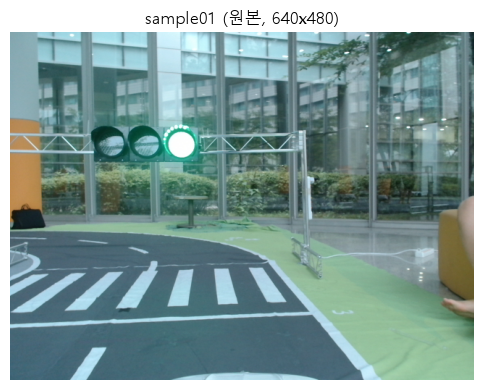

In [2]:
import camera_perception_func_lib as cam
# 실습용 이미지 한 장 로드
img = cv2.imread(str(SAMPLES/'sample01.png'))
show(img, 'sample01 (원본, 640x480)')


## 1) 원근 변환 (BEV)
카메라로 비스듬히 본 도로를 **위에서 내려다본 시점**으로 펴면 차선이 평행하게 보여 분석이 쉬워집니다.
`edge_image_postproc` 함수가 사용하는 것과 **동일한 변환점**(`src_mat`/`dst_mat`)을 써 봅니다.
- `src_mat`: 원본 이미지에서 도로 사다리꼴 네 점
- `dst_mat`: 펼친 뒤 그 네 점이 갈 직사각형 위치


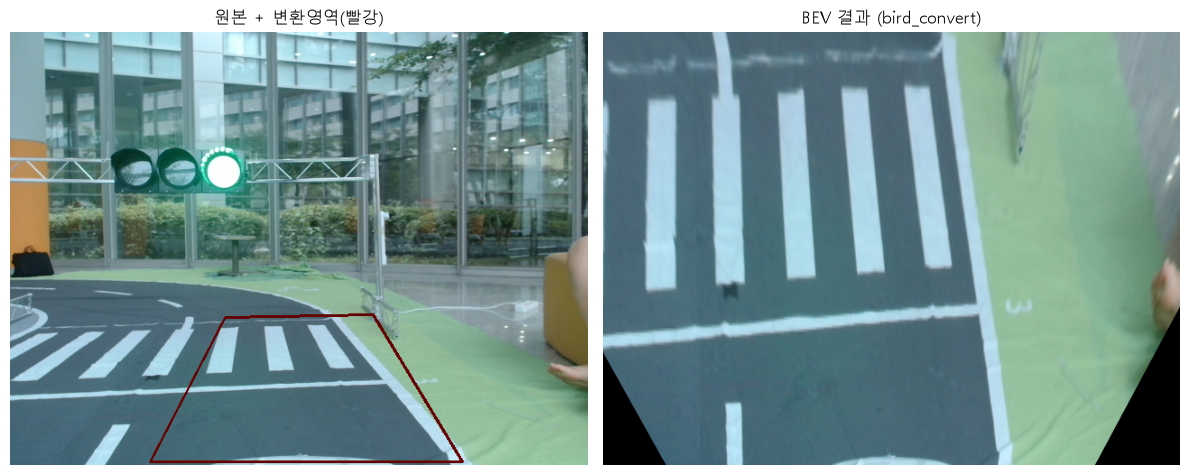

In [3]:
h, w = img.shape[:2]
# camera_perception_func_lib.edge_image_postproc() 내부와 동일한 좌표
src_mat = [[238,316], [402,313], [501,476], [155,476]]
dst_mat = [[round(w*0.3),0], [round(w*0.7),0], [round(w*0.7),h], [round(w*0.3),h]]

# 원본에 src 사다리꼴 그려보기
vis = img.copy()
cv2.polylines(vis, [np.int32(src_mat)], True, (0,0,100), 2)

# 실제 함수로 BEV 변환
bev = cam.bird_convert(img, srcmat=src_mat, dstmat=dst_mat)
show_row([vis, bev], ['원본 + 변환영역(빨강)', 'BEV 결과 (bird_convert)'], figsize=(12,5))


## 2) 관심영역(ROI) 자르기
`roi_rectangle_below(img, cutting_idx)` 는 이미지 위쪽을 잘라내고 **아래쪽(가까운 도로)만** 남깁니다.


BEV shape: (480, 640, 3) -> ROI shape: (180, 640, 3)


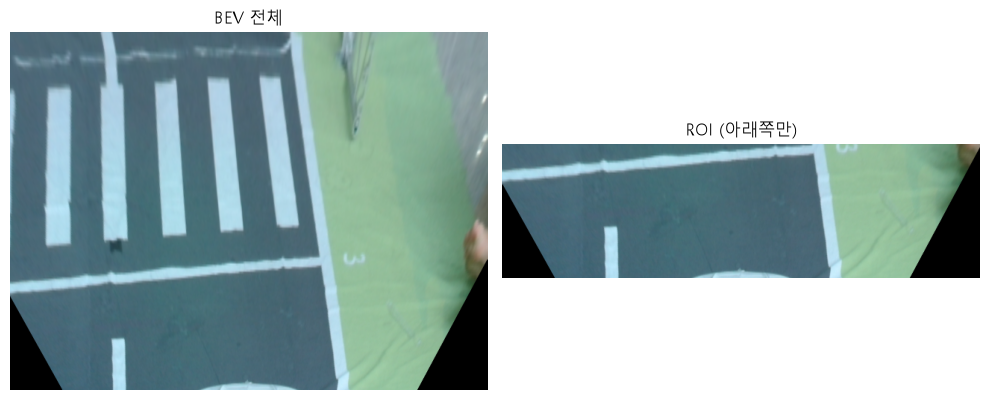

In [4]:
roi = cam.roi_rectangle_below(bev, cutting_idx=300)
print('BEV shape:', bev.shape, '-> ROI shape:', roi.shape)
show_row([bev, roi], ['BEV 전체', 'ROI (아래쪽만)'], figsize=(10,5))


## 3) 차선 기울기 검출 — `dominant_gradient`
`dominant_gradient(binary_image, theta_limit)` 는 **이진(흑백) 차선 이미지**에서 Hough 직선을 찾아
차선들의 **대표 기울기(각도, 도 단위)** 를 반환합니다. 조향 방향 결정에 쓰입니다.

> 실제 파이프라인에서는 YOLOv8 차선 세그멘테이션 결과가 이진 이미지로 들어옵니다.
> 여기서는 독립 실행을 위해 **흰색 차선을 색상 임계값으로 추출**해 비슷한 이진 이미지를 만듭니다.


검출된 차선 대표 기울기: 1.00도  (양수=오른쪽, 음수=왼쪽으로 기울어짐)


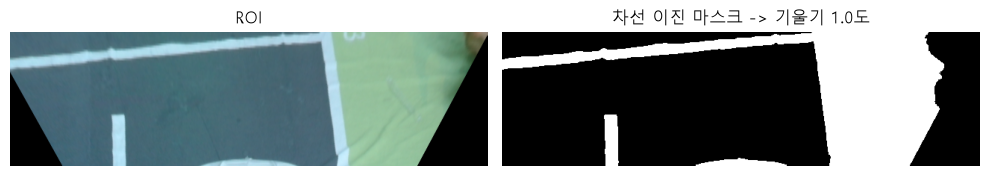

In [8]:
# 흰색 차선만 남기는 간단한 이진화 (YOLO 마스크 대용)
gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
_, lane_mask = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)
lane_mask = cv2.morphologyEx(lane_mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))

# 실제 함수로 대표 기울기 계산 (theta_limit: 수평에 가까운 선 제거 각도)
angle = cam.dominant_gradient(lane_mask, theta_limit=45)
print(f'검출된 차선 대표 기울기: {angle:.2f}도  (양수=오른쪽, 음수=왼쪽으로 기울어짐)')
show_row([roi, lane_mask], ['ROI', f'차선 이진 마스크 -> 기울기 {angle:.1f}도'], figsize=(10,5))


## 4) 차선 중심 좌표 — `get_lane_center`
`get_lane_center` 는 특정 높이(행)에서 차선 픽셀들을 분석해 **차량이 향해야 할 목표 x좌표**를 돌려줍니다.
경로계획(02번 노트북)의 입력이 됩니다.


목표 차선 중심 x = 639.0  (이미지 폭 640)


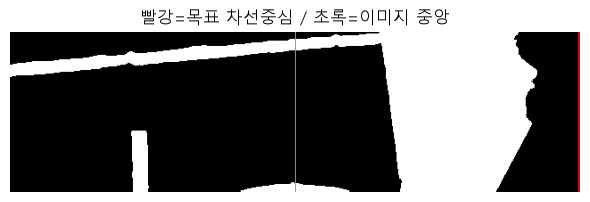

In [9]:
Hm, Wm = lane_mask.shape[:2]
center_x = cam.get_lane_center(
    lane_mask,
    detection_height=Hm//2,     # 마스크 세로 중앙 행에서 탐색
    detection_thickness=10,     # 탐색 밴드 두께
    road_gradient=angle,        # 위에서 구한 기울기
    lane_width=Wm,              # 차선 폭(=이미지 폭)
)
print(f'목표 차선 중심 x = {center_x:.1f}  (이미지 폭 {Wm})')

vis = cv2.cvtColor(lane_mask, cv2.COLOR_GRAY2BGR)
cv2.line(vis, (int(center_x),0), (int(center_x),Hm), (0,0,255), 2)   # 목표 중심(빨강)
cv2.line(vis, (Wm//2,0), (Wm//2,Hm), (0,255,0), 1)                   # 이미지 중앙(초록)
show(vis, '빨강=목표 차선중심 / 초록=이미지 중앙')


## 5) 신호등 색상 판별 — `get_traffic_light_color`
`get_traffic_light_color(image, bbox, hsv_ranges)` 는 신호등 영역(bbox)을 잘라 **HSV 색공간**에서
빨강/노랑/초록 픽셀 비율을 세어 가장 많은 색을 반환합니다.
> 실제로는 YOLO가 신호등 bbox를 넘겨주지만, 여기서는 sample01의 초록불 위치를 직접 지정합니다.


판별된 신호등 색상: Green


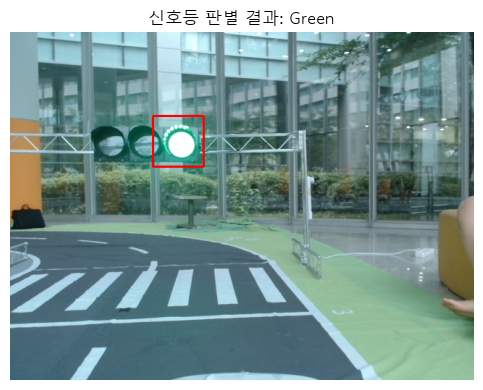

In [10]:
# get_traffic_light_color가 기대하는 bbox 구조를 흉내낸 간단한 객체
class _Pos:  pass
class _Box:  pass
def make_bbox(cx, cy, sx, sy):
    b = _Box(); b.center = _Pos(); b.size = _Pos()
    b.center.position = _Pos()
    b.center.position.x, b.center.position.y = cx, cy
    b.size.x, b.size.y = sx, sy
    return b

# HSV 색상 범위 (H:0-179, S:0-255, V:0-255)
hsv_ranges = {
    'red1':   (np.array([0,100,100]),   np.array([10,255,255])),
    'red2':   (np.array([160,100,100]), np.array([179,255,255])),
    'yellow': (np.array([20,100,100]),  np.array([35,255,255])),
    'green':  (np.array([40,60,60]),    np.array([90,255,255])),
}

light = cv2.imread(str(SAMPLES/'sample01.png'))
bbox = make_bbox(cx=232, cy=150, sx=70, sy=70)   # sample01의 켜진 초록불 위치(대략)
color = cam.get_traffic_light_color(light, bbox, hsv_ranges)
print('판별된 신호등 색상:', color)

x0,y0 = int(bbox.center.position.x-bbox.size.x/2), int(bbox.center.position.y-bbox.size.y/2)
x1,y1 = int(bbox.center.position.x+bbox.size.x/2), int(bbox.center.position.y+bbox.size.y/2)
vis = light.copy(); cv2.rectangle(vis,(x0,y0),(x1,y1),(0,0,255),2)
show(vis, f'신호등 판별 결과: {color}')


---
## 🎯 미션 1 — 원근 변환점 바꿔보기
`src_mat` 의 네 점을 조금씩 바꾸면 BEV 결과가 어떻게 달라질까요?
아래 `# TODO` 의 좌표를 수정해 실행해 보세요.


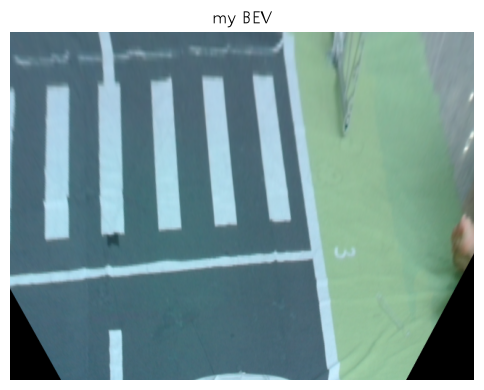

In [9]:
# TODO: 네 점 좌표를 바꿔 BEV가 어떻게 변하는지 관찰하세요
my_src = [[238,316], [402,313], [501,476], [155,476]]   # <- 여기 수정
my_bev = cam.bird_convert(img, srcmat=my_src, dstmat=dst_mat)
show(my_bev, 'my BEV')


**▶ 정답/해설 예시** — 위쪽 두 점을 바깥으로 벌리면 더 넓은 영역이, 안으로 좁히면 더 좁은 영역이 펴집니다.


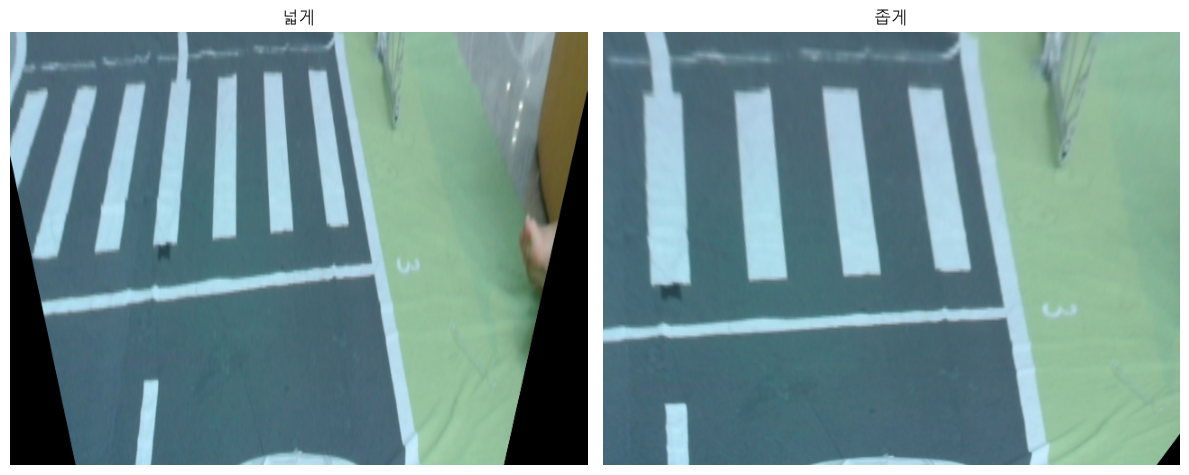

In [10]:
wide_src = [[200,316], [440,313], [501,476], [155,476]]
narrow_src = [[260,316], [380,313], [460,476], [200,476]]
show_row([cam.bird_convert(img, srcmat=wide_src, dstmat=dst_mat),
          cam.bird_convert(img, srcmat=narrow_src, dstmat=dst_mat)],
         ['넓게', '좁게'], figsize=(12,5))


## 🎯 미션 2 — `theta_limit` 실험
`dominant_gradient` 의 `theta_limit` 은 "이 각도보다 수평에 가까운 선은 무시"하는 기준입니다.
값을 10, 30, 60, 80 으로 바꿔가며 검출 기울기가 어떻게 변하는지 표로 확인하세요.


In [11]:
# TODO: theta_list 값을 자유롭게 바꿔보세요
theta_list = [10, 30, 45, 60, 80]
for t in theta_list:
    a = cam.dominant_gradient(lane_mask, theta_limit=t)
    print(f'theta_limit={t:3d}  ->  기울기 {a:6.2f}도')


theta_limit= 10  ->  기울기   3.01도
theta_limit= 30  ->  기울기   4.99도
theta_limit= 45  ->  기울기   1.00도
theta_limit= 60  ->  기울기  10.99도
theta_limit= 80  ->  기울기  14.99도


## 🎯 미션 3 — 다른 샘플 이미지에 전체 파이프라인 적용
`sample02.png` ~ `sample12.png` 중 하나를 골라 **BEV → ROI → 이진화 → 기울기** 전체를 실행하는
함수 `analyze(path)` 를 완성하세요.


In [12]:
def analyze(path):
    im = cv2.imread(str(path))
    # TODO: bird_convert -> roi_rectangle_below -> 임계값 이진화 -> dominant_gradient 순으로 채우기
    ...
    return None

# analyze(SAMPLES/'sample05.jpg')


**▶ 정답 예시**


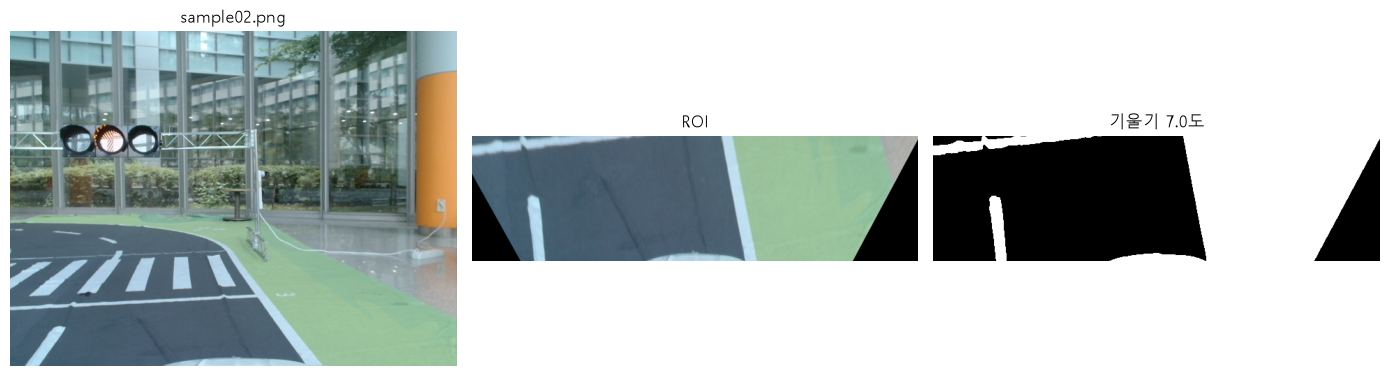

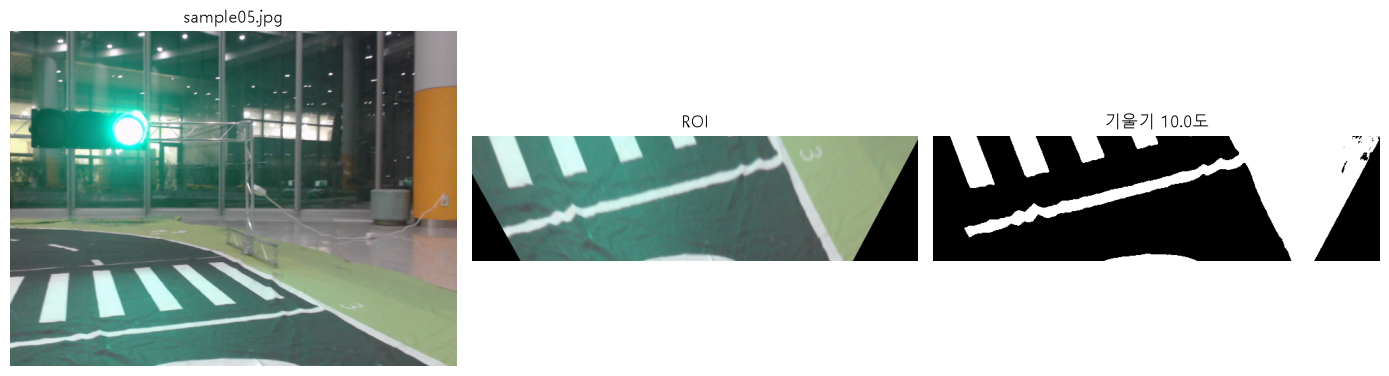

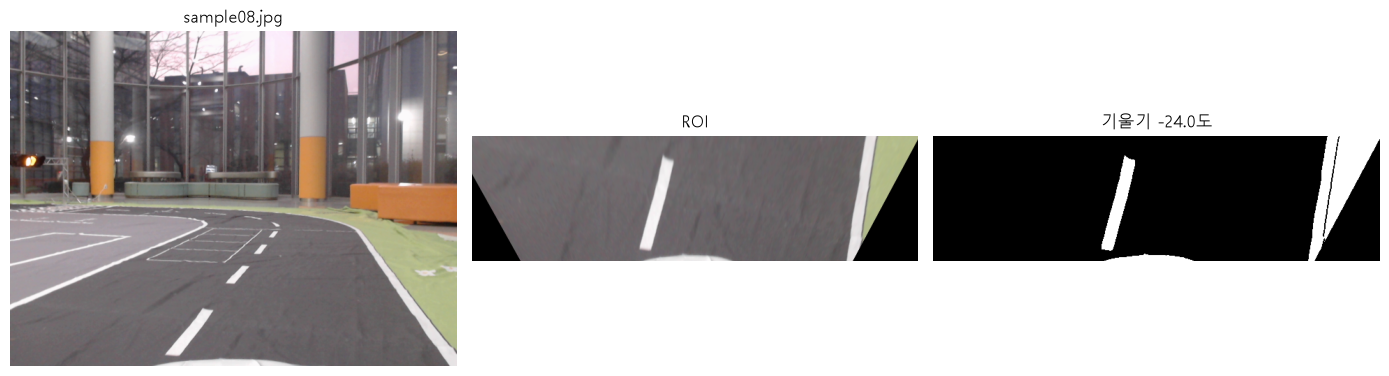

In [13]:
def analyze(path, show_result=True):
    im = cv2.imread(str(path))
    bev = cam.bird_convert(im, srcmat=src_mat, dstmat=dst_mat)
    roi = cam.roi_rectangle_below(bev, 300)
    g = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    _, m = cv2.threshold(g, 150, 255, cv2.THRESH_BINARY)
    ang = cam.dominant_gradient(m, theta_limit=45)
    if show_result:
        show_row([im, roi, m], [Path(path).name, 'ROI', f'기울기 {ang:.1f}도'], figsize=(14,4))
    return ang

for name in ['sample02.png','sample05.jpg','sample08.jpg']:
    analyze(SAMPLES/name)


---
✅ 카메라 인지 완료! 다음은 **`02_판단_경로계획.ipynb`** 입니다.
